## 0. Persiapan Lingkungan dan Dataset

In [1]:
# ==== IDENTITAS (ubah sesuai data Anda) ====
NAMA  = "Khansa Nisrina"
NIM   = "2330511089"          # SEED = 4 digit terakhir NIM
KELAS = "TI-7B"

import os, sys
SEED = int(NIM[-4:])
DI_COLAB = "google.colab" in sys.modules
ROOT = f"/content/simuteh-{NIM}" if DI_COLAB else os.path.abspath(f"simuteh-{NIM}")
for sub in ["data", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(os.path.join(ROOT, sub), exist_ok=True)
os.chdir(ROOT)
print("Folder kerja :", ROOT)
print("SEED         :", SEED)

Folder kerja : /content/simuteh-2330511089
SEED         : 1089


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
%%writefile src/buat_dataset_sintetis.py
"""
buat_dataset_sintetis.py
Membangkitkan dataset citra sintetis daun teh untuk studi kasus SIMUTEH.
Setiap mahasiswa memakai SEED = 4 digit terakhir NIM sehingga datanya berbeda.

Keluaran (folder data/sintetis/):
  citra/    citra berwarna hasil "pemotretan" (dengan gangguan cahaya dan derau)
  bersih/   citra yang sama tanpa gangguan (acuan mutu)
  mask_daun/    mask area daun (255 = daun)
  mask_bercak/  mask area bercak penyakit (255 = bercak)
  label.csv     nama_file, kelas, kondisi_cahaya, persen_bercak
"""
import os
import csv
import cv2
import numpy as np

SEED = 1089          # GANTI dengan 4 digit terakhir NIM Anda
N_PER_KELAS = 20     # 20 citra x 3 kelas = 60 citra
H, W = 480, 640
KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
OUT = os.path.join("data", "sintetis")

rng = np.random.default_rng(SEED)


def gambar_daun(img, mask):
    """Menggambar satu helai daun berbentuk elips beserta tulang daunnya."""
    cx = int(rng.integers(260, 380))
    cy = int(rng.integers(200, 280))
    ax = int(rng.integers(190, 240))
    ay = int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))
    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150),
                      rng.integers(45, 75)])               # BGR
    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)
    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)
    # tulang daun utama dan cabang
    t = np.deg2rad(sudut)
    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))
    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))
    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)
    for k in np.linspace(-0.7, 0.7, 6):
        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)
        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)
            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)
    return mask


def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    """Menambahkan bercak cacar daun (pucat kekuningan, tepi kecokelatan)."""
    if kelas == "sehat":
        return
    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))
    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)
    ys, xs = np.where(mask_daun > 0)
    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))
        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)),
                 int(rng.integers(185, 210))]               # BGR pucat
        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)    # tepi cokelat
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)
    mask_bercak &= mask_daun                                # bercak hanya di daun


def ganggu_cahaya(img, kondisi):
    """Mensimulasikan kondisi pemotretan di lapangan."""
    f = img.astype(np.float32)
    if kondisi == "gelap":
        f = 255 * (f / 255) ** 2.0
    elif kondisi == "terang":
        f = 255 * (f / 255) ** 0.45
    elif kondisi == "kontras_rendah":
        f = 0.35 * f + 95
    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)   # separuh teduh
        f = f * gx[None, :, None]
    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)                   # derau sensor
    return np.clip(f, 0, 255).astype(np.uint8)


def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)
    baris = []
    nomor = 0
    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1
            latar = np.array([rng.integers(150, 190), rng.integers(170, 205),
                              rng.integers(185, 215)])      # nampan anyaman
            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)
            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))
            m_daun = np.zeros((H, W), np.uint8)
            m_bercak = np.zeros((H, W), np.uint8)
            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)
            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]
            citra = ganggu_cahaya(bersih, kondisi)
            nama = f"teh_{nomor:03d}.png"
            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)
            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)
            baris.append([nama, kelas, kondisi, round(persen, 2)])
    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])
        w.writerows(baris)
    print(f"Selesai: {nomor} citra tersimpan di {OUT}")


if __name__ == "__main__":
    main()


Writing src/buat_dataset_sintetis.py


In [4]:
%%writefile src/utils_cv.py
"""utils_cv.py: fungsi bantu yang dipakai ulang sepanjang semester."""
import cv2
import numpy as np
import matplotlib.pyplot as plt


def baca(path):
    """Membaca citra dan langsung memberi pesan jelas bila gagal."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")
    return img


def tampil(daftar, judul, baris=1, ukuran=(14, 4)):
    """Menampilkan beberapa citra berdampingan. Citra 3 kanal dianggap BGR."""
    kolom = int(np.ceil(len(daftar) / baris))
    plt.figure(figsize=ukuran)
    for i, (im, jd) in enumerate(zip(daftar, judul)):
        plt.subplot(baris, kolom, i + 1)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(jd)
        plt.axis("off")
    plt.tight_layout()


def kontras_bercak(kanal, mask_daun, mask_bercak):
    """KB = |rerata bercak - rerata daun sehat| / simpangan baku daun sehat.
    Makin besar KB, makin mudah bercak dipisahkan dari daun sehat."""
    k = kanal.astype(np.float64)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    if bercak.sum() == 0:
        return float("nan")
    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)


def statistik(gray):
    """Ringkasan statistik intensitas untuk mendiagnosis mutu citra."""
    return {"rerata": round(float(gray.mean()), 1),
            "simpangan_baku": round(float(gray.std()), 1),
            "min": int(gray.min()), "maks": int(gray.max()),
            "persen_gelap": round(100 * float((gray < 50).mean()), 1),
            "persen_terang": round(100 * float((gray > 205).mean()), 1)}


Writing src/utils_cv.py


In [ ]:
# Pasang SEED sesuai NIM, bangkitkan dataset, lalu pindah ke folder notebook/
import re, subprocess
kode = open("src/buat_dataset_sintetis.py").read()
kode = re.sub(r"^SEED = \d+", f"SEED = {SEED}", kode, count=1, flags=re.M)
open("src/buat_dataset_sintetis.py", "w").write(kode)
keluaran = subprocess.run([sys.executable, "src/buat_dataset_sintetis.py"],
                          capture_output=True, text=True)
print(keluaran.stdout, keluaran.stderr)

# requirements.txt untuk reprodusibilitas
import cv2, numpy, pandas, matplotlib, skimage, PIL
with open("requirements.txt", "w") as f:
    for nm, m in [("opencv-python", cv2), ("numpy", numpy), ("pandas", pandas),
                  ("matplotlib", matplotlib), ("scikit-image", skimage), ("pillow", PIL)]:
        f.write(f"{nm}=={m.__version__}\n")
print(open("requirements.txt").read())

os.chdir(os.path.join(ROOT, "notebook"))   # semua jalur selanjutnya diawali ../

In [ ]:
# Pustaka dan fungsi bantu yang dipakai di seluruh notebook
sys.path.append("../src")
import time, json
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, tampil, kontras_bercak, statistik

pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 90

def muat(nama, folder="citra"):
    """Mengembalikan (citra BGR, mask daun, mask bercak) untuk satu nama berkas."""
    img = baca(f"../data/sintetis/{folder}/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat| (satuan intensitas)."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
print(label.groupby(["kelas", "kondisi_cahaya"]).size().unstack())
print(label.groupby("kelas").persen_bercak.describe().round(2))

kondisi_cahaya  bayangan  gelap  kontras_rendah  normal  terang
kelas                                                          
berat                  4      4               4       4       4
ringan                 4      4               4       4       4
sehat                  4      4               4       4       4
        count  mean   std   min   25%   50%   75%   max
kelas                                                  
berat    20.0  4.67  1.27  2.69  3.52  4.90  5.71  6.82
ringan   20.0  0.43  0.21  0.10  0.30  0.44  0.62  0.78
sehat    20.0  0.00  0.00  0.00  0.00  0.00  0.00  0.00


## Bagian 1. Lingkungan Kerja dan Formulasi Masalah
### Kode 1.1 Uji lingkungan dan struktur larik citra

OpenCV 5.0.0 | NumPy 2.4.6 | scikit-image 0.25.2
shape: (480, 640, 3) dtype: uint8
min-maks: 0 255
piksel (y=100, x=200) dalam urutan BGR: [161 211 178]


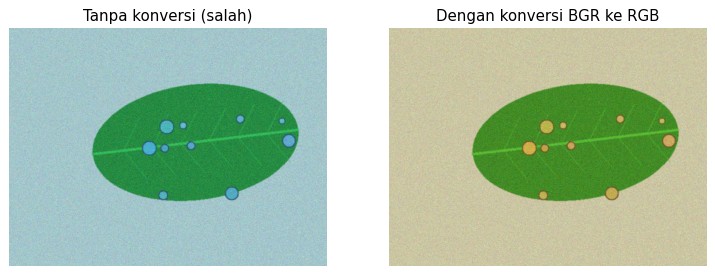

Potongan 5x5 nilai keabuan di sekitar (y, x) = (237, 384)
[[ 95 102 102 124 101]
 [110 111  88 109  94]
 [101 105 104 116  94]
 [105 110 108 109 102]
 [107 115  97 104  97]]


In [ ]:
import skimage
print("OpenCV", cv2.__version__, "| NumPy", np.__version__,
      "| scikit-image", skimage.__version__)
img = baca("../data/sintetis/citra/teh_041.png")
print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img); plt.title("Tanpa konversi (salah)"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB"); plt.axis("off")
plt.savefig("../hasil/b1_bgr_rgb.png", bbox_inches="tight"); plt.show()

# contoh semantic gap: potongan 5 x 5 kanal keabuan di sekitar bercak
md0 = cv2.imread("../data/sintetis/mask_bercak/teh_041.png", 0)
ys, xs = np.where(md0 > 0)
cy, cx = int(ys.mean()), int(xs.mean())
gray0 = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("Potongan 5x5 nilai keabuan di sekitar (y, x) =", (cy, cx))
print(gray0[cy-2:cy+3, cx-2:cx+3])

### Problem Statement SIMUTEH

> Bagi **petugas sortir kelompok tani teh rakyat di Kabupaten Sukabumi** yang menghadapi **penilaian mutu daun secara manual yang lambat dan tidak seragam, terutama saat cahaya tidak merata dan bercak cacar daun masih kecil**, kami membangun **SIMUTEH, sistem pemeriksaan mutu daun berbasis citra** yang menerima **foto daun di atas nampan sortir dari kamera telepon genggam** dan menghasilkan **kelas mutu (Sehat, Bercak Ringan, Bercak Berat) beserta persentase luas bercak terhadap luas daun**, sehingga **penyortiran lebih cepat, lebih seragam, dan keputusan akhir petugas didukung bukti yang terukur**.

### Diagram Pipeline SIMUTEH

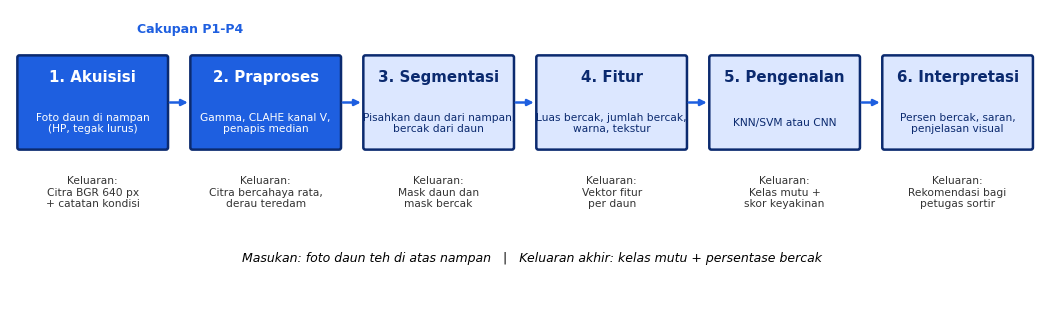

In [ ]:
from matplotlib.patches import FancyBboxPatch
tahap = [
  ("1. Akuisisi", "Foto daun di nampan\n(HP, tegak lurus)", "Citra BGR 640 px\n+ catatan kondisi"),
  ("2. Praproses", "Gamma, CLAHE kanal V,\npenapis median", "Citra bercahaya rata,\nderau teredam"),
  ("3. Segmentasi", "Pisahkan daun dari nampan,\nbercak dari daun", "Mask daun dan\nmask bercak"),
  ("4. Fitur", "Luas bercak, jumlah bercak,\nwarna, tekstur", "Vektor fitur\nper daun"),
  ("5. Pengenalan", "KNN/SVM atau CNN", "Kelas mutu +\nskor keyakinan"),
  ("6. Interpretasi", "Persen bercak, saran,\npenjelasan visual", "Rekomendasi bagi\npetugas sortir"),
]
fig, ax = plt.subplots(figsize=(15, 4.2)); ax.set_xlim(0, 15); ax.set_ylim(0, 4.2); ax.axis("off")
for i, (nm, proses, keluar) in enumerate(tahap):
    x = 0.15 + i * 2.48
    ax.add_patch(FancyBboxPatch((x, 2.2), 2.1, 1.3, boxstyle="round,pad=0.03",
                                fc="#1E5FE0" if i < 2 else "#DCE7FF", ec="#0B2A6F", lw=2))
    ax.text(x + 1.05, 3.15, nm, ha="center", fontsize=12, weight="bold",
            color="white" if i < 2 else "#0B2A6F")
    ax.text(x + 1.05, 2.55, proses, ha="center", va="center", fontsize=8.5,
            color="white" if i < 2 else "#0B2A6F")
    ax.text(x + 1.05, 1.55, "Keluaran:\n" + keluar, ha="center", va="center", fontsize=8.5, color="#333")
    if i < 5:
        ax.annotate("", xy=(x + 2.45, 2.85), xytext=(x + 2.12, 2.85),
                    arrowprops=dict(arrowstyle="-|>", color="#1E5FE0", lw=2))
ax.text(7.5, 0.55, "Masukan: foto daun teh di atas nampan   |   Keluaran akhir: kelas mutu + persentase bercak",
        ha="center", fontsize=10, style="italic")
ax.text(2.6, 3.85, "Cakupan P1-P4", ha="center", fontsize=10, color="#1E5FE0", weight="bold")
plt.savefig("../hasil/b1_pipeline.png", bbox_inches="tight", dpi=150); plt.show()

### Tabel Risiko Responsible Computer Vision

In [ ]:
risiko = pd.DataFrame([
 ["Privasi citra", "Foto memuat wajah petugas atau metadata EXIF berisi lokasi GPS kebun",
  "Foto hanya bidang nampan; hapus EXIF otomatis sebelum disimpan; izin pemilik kebun"],
 ["Bias dan keadilan", "Data latih didominasi satu varietas, satu kebun, atau cahaya normal sehingga daun dari kebun lain lebih sering salah dinilai",
  "Rencana akuisisi mewakili 5 kondisi cahaya dan beberapa kebun; evaluasi kinerja per kondisi dan per sumber"],
 ["Transparansi", "Petani tidak tahu dasar sistem menilai daun berbercak berat",
  "Tampilkan mask bercak dan persen bercak di samping kelas mutu; jelaskan keterbatasan"],
 ["Keamanan data", "Repository atau penyimpanan cloud terbuka untuk umum",
  "Repository privat; akses hanya anggota tim; foto mentah tidak diunggah"],
 ["Dampak sosial", "Daun sehat dinilai berbercak sehingga harga jual petani turun; keputusan sepenuhnya diserahkan ke mesin",
  "SIMUTEH hanya alat bantu; keputusan akhir di tangan petugas; ambang kelas dikonsultasikan dengan kelompok tani"],
 ["Keterlacakan", "Hasil tidak dapat diulang karena parameter praproses tidak dicatat",
  "SEED, versi pustaka (requirements.txt), dan param_praproses.json disimpan di repository"],
], columns=["Aspek", "Risiko pada SIMUTEH", "Mitigasi awal"])
risiko.to_csv("../hasil/b1_risiko_rcv.csv", index=False)
display(risiko)

,Aspek,Risiko pada SIMUTEH,Mitigasi awal
0,Privasi citra,Foto memuat wajah petugas atau metadata EXIF b...,Foto hanya bidang nampan; hapus EXIF otomatis ...
1,Bias dan keadilan,"Data latih didominasi satu varietas, satu kebu...",Rencana akuisisi mewakili 5 kondisi cahaya dan...
2,Transparansi,Petani tidak tahu dasar sistem menilai daun be...,Tampilkan mask bercak dan persen bercak di sam...
3,Keamanan data,Repository atau penyimpanan cloud terbuka untu...,Repository privat; akses hanya anggota tim; fo...
4,Dampak sosial,Daun sehat dinilai berbercak sehingga harga ju...,SIMUTEH hanya alat bantu; keputusan akhir di t...
5,Keterlacakan,Hasil tidak dapat diulang karena parameter pra...,"SEED, versi pustaka (requirements.txt), dan pa..."


### Jawaban Pertanyaan Analisis Bagian 1

**P1.1 Semantic gap.** Petugas sortir melihat "daun teh dengan beberapa bercak pucat kekuningan" dan langsung tahu daun itu bermutu rendah. Komputer hanya menerima larik `uint8` berukuran (480, 640, 3) berisi 921.600 angka 0 sampai 255 dalam urutan BGR. Contohnya, piksel (y=100, x=200) bernilai [163 193 193], yaitu warna nampan, dan potongan 5 x 5 keabuan di dekat bercak berisi angka sekitar 87 sampai 129 yang tidak mengandung kata "bercak". Jarak antara angka-angka ini dan makna "daun berbercak berat" itulah semantic gap. SIMUTEH menjembataninya lewat tahap pipeline: praproses, segmentasi bercak, pengukuran luas, lalu klasifikasi.

**P1.2 Tiga sumber variasi yang paling mengganggu SIMUTEH.**
1. *Pencahayaan* (teduh, terik, bayangan atap). Ditangani pada tahap **akuisisi** (protokol pemotretan) dan **praproses** (gamma, CLAHE).
2. *Skala dan jarak* (petugas memotret dari jarak berbeda). Ditangani pada **akuisisi** (jarak tetap sekitar 20 cm, acuan ukuran berupa koin) dan pada **fitur** (memakai persentase luas bercak terhadap luas daun, bukan luas absolut).
3. *Derau dan latar* (derau sensor HP murah, nampan anyaman bertekstur). Ditangani pada **praproses** (penapis median) dan **segmentasi** (memisahkan daun dari nampan).
Oklusi (daun bertumpuk) juga mungkin terjadi dan ditangani pada tahap **pengenalan** dengan deteksi objek (P13).

**P1.3 BGR dan RGB.** OpenCV menyimpan kanal dalam urutan B, G, R, sedangkan Matplotlib menganggap R, G, B. Tanpa konversi, kanal merah dan biru tertukar: nampan krem tampak kebiruan dan bercak kuning tampak biru, sedangkan daun hijau hampir tidak berubah karena kanal G tetap di tengah. Bila kesalahan ini terbawa ke P9, fitur warna seperti "rerata kanal merah" sebenarnya dihitung dari kanal biru. Model akan belajar dari ciri yang salah, dan bila konversi saat pelatihan berbeda dengan saat pemakaian, prediksi menjadi kacau.

**P1.4 Dampak kesalahan.**
* *Daun sehat dinilai bercak berat (positif palsu):* yang dirugikan adalah petani, karena harga turun atau daun dibuang. Yang diuntungkan secara tidak adil adalah pembeli.
* *Daun berbercak berat dinilai sehat (negatif palsu):* yang dirugikan adalah pabrik atau pembeli, karena mutu teh turun. Kelompok tani juga dirugikan dalam jangka panjang: reputasinya turun dan penyakit dapat menyebar ke kebun lain.

Nilai **adil** menuntut kesalahan tidak lebih sering terjadi pada kelompok tertentu, misalnya kebun yang teduh atau difoto dengan HP murah. Karena itu evaluasi harus dilakukan per kondisi, bukan hanya rerata. Nilai **amanah** menuntut SIMUTEH disampaikan sebagai alat bantu beserta keterbatasannya, dengan keputusan akhir tetap di tangan petugas sortir.